# Enhancer–gene regulation from random walks + selective SSMs

## 1. Data
Raw data comes from `download_data.sh` (sources listed there). Here we preprocess everything into three tables:
`crispr` (labeled pairs), `nodes` (candidate elements = graph nodes), and `hic` (contacts between node bins).

In [1]:
import os, multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from concurrent.futures.process import BrokenProcessPool
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pyranges as pr, pysam, pyfaidx, hicstraw

RAW = Path(os.environ.get("E2G_DATA_DIR", "data")) / "raw"
PROC = RAW.parent / "processed"; PROC.mkdir(exist_ok=True)
CHROMS = [f"chr{i}" for i in range(1, 23)] + ["chrX"]
HIC_URL = "https://encode-public.s3.amazonaws.com/2022/05/15/0571c671-3645-4f92-beae-51dfd3f42c36/ENCFF621AIY.hic"  # public bucket, no redirect
RES, MAX_DIST = 5_000, 5_000_000   # Hi-C bin size and max contact distance (ABC defaults)
BAMS = [str(RAW / "ENCFF512VEZ.bam"), str(RAW / "ENCFF987XOV.bam")]

PR = lambda df: pr.PyRanges(df.rename(columns={"chrom": "Chromosome", "start": "Start", "end": "End"}))
DF = lambda g: g.df.rename(columns={"Chromosome": "chrom", "Start": "start", "End": "end"})

### CRISPR benchmark

In [2]:
genes = pd.read_csv(RAW / "CollapsedGeneBounds.hg38.bed", sep="\t").rename(columns={"#chr": "chrom", "name": "gene"})
genes = genes[genes.chrom.isin(CHROMS)].assign(tss=lambda d: np.where(d.strand == "+", d.start, d.end - 1))

crispr = pd.read_csv(RAW / "EPCrisprBenchmark_combined_data.training_K562.GRCh38.tsv.gz", sep="\t").rename(
    columns={"chromStart": "start", "chromEnd": "end", "measuredGeneSymbol": "gene", "Regulated": "label"})
# Gene TSS from the ABC list: it reproduces the benchmark's distanceToTSS exactly (the startTSS column doesn't).
crispr["tss"] = crispr.gene.map(genes.set_index("gene").tss)
crispr["center"] = (crispr.start + crispr.end) // 2
crispr = crispr[["chrom", "start", "end", "center", "gene", "tss", "distanceToTSS", "label", "Dataset"]]
crispr.groupby("Dataset").label.agg(pairs="size", positives="sum", rate="mean")

,pairs,positives,rate
Dataset,,,
Gasperini2019,5299,360,0.067937
Nasser2021,3751,88,0.023460
Schraivogel2020,1306,23,0.017611


### Candidate elements (nodes)
ABC recipe: ATAC summit ±250 bp windows, merged, plus every promoter (TSS ±250 bp), minus blocklist. ENCODE's peak set has <150k distinct regions, so ABC's top-150k cut keeps everything.

In [3]:
block = PR(pd.read_csv(RAW / "GRCh38_unified_blacklist.bed", sep="\t", header=None, usecols=[0, 1, 2], names=["chrom", "start", "end"]))
peaks = pd.read_csv(RAW / "ENCFF558BLC.bed.gz", sep="\t", header=None, usecols=[0, 1, 9], names=["chrom", "start", "summit"])
peaks = peaks[peaks.chrom.isin(CHROMS)].assign(start=lambda d: (d.start + d.summit - 250).clip(lower=0)).drop_duplicates(["chrom", "start"])
promoters = genes.assign(start=genes.tss - 250, end=genes.tss + 250)
nodes = DF(pr.concat([PR(peaks.assign(end=peaks.start + 500)), PR(promoters)]).merge().overlap(block, invert=True))

In [4]:
nodes = nodes.assign(chrom=pd.Categorical(nodes.chrom, CHROMS, ordered=True)).sort_values(["chrom", "start"], ignore_index=True)
nodes = nodes.assign(chrom=nodes.chrom.astype(str), node_id=nodes.index, center=(nodes.start + nodes.end) // 2)
count_reads = lambda df: sum(np.array([b.count(c, s, e) for c, s, e in zip(df.chrom, df.start, df.end)]) for b in map(pysam.AlignmentFile, BAMS))
total_reads = sum(s.mapped for b in BAMS for s in pysam.AlignmentFile(b).get_index_statistics() if s.contig in CHROMS)
nodes["log_atac"] = np.log1p(count_reads(nodes) / total_reads * 1e6)   # a_v = log(1 + RPM)
nodes["is_promoter"] = nodes.node_id.isin(DF(PR(nodes).overlap(PR(promoters))).node_id)
fa = pyfaidx.Fasta(str(RAW / "hg38.fa"), as_raw=True, sequence_always_upper=True)
nodes["sequence"] = [fa[c][s:e] for c, s, e in zip(nodes.chrom, nodes.start, nodes.end)]
print(f"{len(nodes):,} nodes, {nodes.is_promoter.sum():,} promoters")

111,311 nodes, 19,300 promoters


### Map benchmark pairs to nodes
Element → node with largest overlap (−1 if none; scored 0 at eval, as in ENCODE-rE2G). Gene → node containing its TSS.

In [5]:
nodes_pr = PR(nodes[["chrom", "start", "end", "node_id"]])
j = DF(PR(crispr.reset_index()).join(nodes_pr, report_overlap=True)).sort_values("Overlap").drop_duplicates("index", keep="last")
crispr["elem_node"] = j.set_index("index").node_id.reindex(crispr.index).fillna(-1).astype(int)
t = DF(PR(crispr.reset_index().assign(start=lambda d: d.tss, end=lambda d: d.tss + 1)).join(nodes_pr))
crispr["gene_node"] = t.set_index("index").node_id.reindex(crispr.index).fillna(-1).astype(int)
crispr.assign(elem_in_graph=crispr.elem_node >= 0, gene_in_graph=crispr.gene_node >= 0).groupby("label")[["elem_in_graph", "gene_in_graph"]].mean()

,elem_in_graph,gene_in_graph
label,,
False,0.787355,0.999798
True,0.887473,1.000000


In [6]:
crispr.to_parquet(PROC / "crispr.parquet"); nodes.to_parquet(PROC / "nodes.parquet")   # hic is cached in PROC / "hic"

### Hi-C
Streamed from ENCODE (no 34 GB download). Keeps SCALE-normalized observed and O/E between bins that contain a node or benchmark element/TSS, within 5 Mb.

In [7]:
bins = pd.concat([pd.DataFrame({"chrom": d.chrom, "bin": x // RES * RES})
                  for d, x in [(nodes, nodes.center), (crispr, crispr.center), (crispr, crispr.tss)]]).groupby("chrom").bin.unique()
CHROM_LEN = {c.name: c.length for c in hicstraw.HiCFile(HIC_URL).getChromosomes()}

def fetch_hic(chrom):
    path = PROC / "hic" / f"{chrom}.parquet"   # per-chromosome cache
    if path.exists(): return pd.read_parquet(path)
    f = hicstraw.HiCFile(HIC_URL)
    obs, oe = (f.getMatrixZoomData(chrom, chrom, k, "SCALE", "BP", RES) for k in ("observed", "oe"))
    oe.getRecords(0, RES, 0, RES); expected = np.asarray(oe.getExpectedValues())   # O/E = observed / expected[distance]
    assert len(expected), f"{chrom}: incomplete remote read"
    L, out = CHROM_LEN[chrom], []
    for s in range(0, L, MAX_DIST):   # 5 Mb row blocks x (block + 5 Mb) columns
        a = np.array([(r.binX, r.binY, r.counts) for r in obs.getRecords(s, min(s + MAX_DIST, L) - 1, s, min(s + 2 * MAX_DIST, L) - 1)]).reshape(-1, 3)
        b1, b2 = np.minimum(a[:, 0], a[:, 1]).astype(int), np.maximum(a[:, 0], a[:, 1]).astype(int)
        m = (b1 >= s) & (b1 < s + MAX_DIST) & (b2 - b1 <= MAX_DIST) & np.isin(b1, bins[chrom]) & np.isin(b2, bins[chrom])
        out.append(pd.DataFrame({"chrom": chrom, "bin1": b1[m], "bin2": b2[m], "observed": a[m, 2]}))
    df = pd.concat(out).drop_duplicates(["bin1", "bin2"])
    df = df.assign(oe=df.observed / expected[(df.bin2 - df.bin1) // RES]).dropna()
    df.to_parquet(path, index=False); return df

def fetch_hic_retry(chrom, tries=3):  # remote reads occasionally time out
    for i in range(tries):
        try: return fetch_hic(chrom)
        except Exception as e: print(f"{chrom} attempt {i + 1} failed: {e}")
    raise RuntimeError(chrom)

(PROC / "hic").mkdir(exist_ok=True)
for _ in range(5):   # hicstraw can crash a worker on network errors; restart the pool on the remaining chromosomes
    todo = sorted([c for c in CHROMS if not (PROC / "hic" / f"{c}.parquet").exists()], key=CHROM_LEN.get, reverse=True)
    try:
        with ProcessPoolExecutor(4, mp_context=mp.get_context("fork")) as ex:   # hicstraw holds the GIL -> processes, not threads
            list(ex.map(fetch_hic_retry, todo))
    except BrokenProcessPool:
        print("worker crashed; restarting")
hic = pd.read_parquet(PROC / "hic")
print(f"{len(hic):,} contacts")
hic.groupby("chrom").size().div(bins.map(len)).describe().round(1)   # contacts per bin: flags a chromosome with failed blocks

5,741,654 contacts


count    23.0
mean     55.7
std      12.9
min      32.2
25%      49.6
50%      54.7
75%      63.0
max      81.9
dtype: float64

### Summary statistics: contact distances
Hi-C files store only nonzero pairs. Past ~500 kb a 5 kb bin pair expects <1 read, so stored pairs have inflated O/E (single-read noise): Hi-C edges will need a minimum observed count, not just O/E ≥ τ.

count   mean    std  min   10%    50%     90%     max
Dataset         label                                                        
Gasperini2019   False  4939.0  465.0  294.3  1.2  77.4  442.4   886.6  1056.6
                True    360.0   84.4  157.4  1.4   3.6   29.7   207.6  1031.5
Nasser2021      False  3663.0  482.0  474.2  1.9  64.2  317.6  1248.4  2375.1
                True     88.0  147.6  445.7  1.3   2.3   21.3   223.3  1962.1
Schraivogel2020 False  1283.0  440.8  288.6  8.4  86.8  402.6   869.5  1117.7
                True     23.0   48.7   94.7  1.3   3.5   20.4    48.0   454.2

observed                                               \
                      count    mean     std  min     25%     50%     75%   
dist_kb                                                                    
(-0.001, 10.0]     157617.0  264.72  169.90  0.0  114.20  254.60  391.74   
(10.0, 50.0]       246227.0   19.34   16.74  0.0   10.69   16.56   24.83   
(50.0, 100.0]      289400.0    9.26   12.56  0.0    4.61    7.53   11.55   
(100.0, 500.0]    1723832.0    3.65    7.48  0.0    1.31    2.44    4.43   
(500.0, 1000.0]   1107220.0    1.47    5.82  0.0    0.71    1.06    1.69   
(1000.0, 5000.0]  2217358.0    0.93    6.26  0.0    0.55    0.73    1.02   

                                  oe                                      \
                      max      count  mean    std  min   25%   50%   75%   
dist_kb                                                                    
(-0.001, 10.0]    2703.64   157617.0  1.05   0.32  0.0  0.87  1.03  1.20   
(10.0, 50.0]      2880.65   246227.0  1.37   1.25  0.0  0.92  1.22  1.62   
(50.0, 100.0]     1944.41   289400.0  1.59   2.14  0.0  0.84  1.29  1.93   
(100.0, 500.0]    2472.46  1723832.0  1.68   3.80  0.0  0.75  1.25  2.03   
(500.0, 1000.0]   2836.26  1107220.0  2.12   9.72  0.0  1.03  1.59  2.48   
(1000.0, 5000.0]  2819.55  2217358.0  6.85  64.14  0.0  2.77  4.77  8.09   

                            
                       max  
dist_kb                     
(-0.001, 10.0]       29.67  
(10.0, 50.0]        245.16  
(50.0, 100.0]       415.46  
(100.0, 500.0]     1631.18  
(500.0, 1000.0]    3636.49  
(1000.0, 5000.0]  33485.22

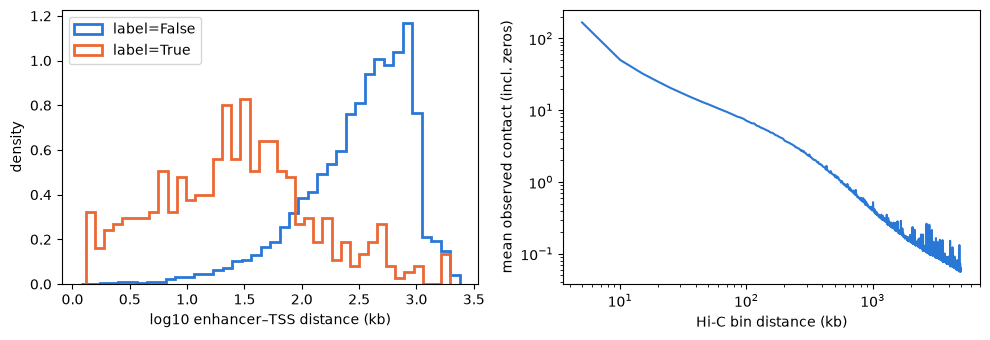

In [8]:
from scipy.signal import fftconvolve
crispr["dist_kb"] = crispr.distanceToTSS.abs() / 1e3
hic["dist_kb"] = (hic.bin2 - hic.bin1) / 1e3
display(crispr.groupby(["Dataset", "label"]).dist_kb.describe(percentiles=[.1, .5, .9]).round(1))
display(hic.groupby(pd.cut(hic.dist_kb, [0, 10, 50, 100, 500, 1000, 5000], include_lowest=True), observed=True)[["observed", "oe"]].describe().round(2))

# Distance decay including zero pairs: total contact at each distance / number of bin pairs of interest at that distance.
n_pairs = sum(np.rint(fftconvolve(x := np.bincount(b // RES).astype(float), x[::-1])[len(x) - 1:][:MAX_DIST // RES + 1]) for b in bins)
decay = hic.groupby((hic.bin2 - hic.bin1) // RES)["observed"].sum().pipe(lambda t: t / n_pairs[t.index])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for lab, c in [(False, "#2a78d6"), (True, "#eb6834")]:
    ax[0].hist(np.log10(crispr.dist_kb[crispr.label == lab]), bins=40, density=True, histtype="step", lw=2, color=c, label=f"label={lab}")
ax[0].set(xlabel="log10 enhancer–TSS distance (kb)", ylabel="density"); ax[0].legend()
ax[1].loglog(decay.index[1:] * RES / 1e3, decay.values[1:], color="#2a78d6"); ax[1].set(xlabel="Hi-C bin distance (kb)", ylabel="mean observed contact (incl. zeros)")
plt.tight_layout()